# Exploratory Data Analysis (train, edges_raw)

Train findings:
* Only the `label` has NA rows. all other feature rows are fully filled
* Total train rows: 141772
* Usable labeled rows for training: 31235 (22.03%)
* Unlabeled rows (unusable for supervised training): 110537 (77.97%)
* Licit (0): 27591 | Illicit (1): 3644 (11.67% illicit)

Edgelist findings:
* there are no self-payments and no duplicated transactions

Comparing differences between Labelled and NAs (Train):
* As the goal is semi-suervised learning, I want to assess if there are any significant differences in the feature distributions of the lablled vs NA rows
* time_step 6 and time_step 33 notably occupy the top 10 most different feature distributions between the labelled and NA rows
* As such, the proportion of illicit rows in the labelled may not be the same as the NA rows (as we do not know the ground truth of the NA rows)
* due to the uncertainty, I will be using soft labelling.

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


from scipy.stats import ks_2samp

from statsmodels.stats.multitest import multipletests

In [2]:
### Load data

train_raw = pd.read_csv("train.csv", header = 0)
test_raw = pd.read_csv("test.csv", header = 0)
edges_raw = pd.read_csv("txs_edgelist.csv", header = 0)
sample_submission = pd.read_csv("sample_submission.csv", header = 0)
train_soft_label = pd.read_csv("train.csv", header = 0)

### Preview Data

print("train data:\n",train_raw.head(10), "\n")

print("test data:\n", test_raw.head(10), "\n")

# From Kaggle Page, edges is optional to use
print("edges:\n", edges_raw.head(10), "\n")

### Check which columns have NAs
print("check NA columns:")
train_raw.columns[train_raw.isna().any()].tolist()

train data:
         txId  time_step    feat_1    feat_2    feat_3     feat_4    feat_5  \
0  230425980          1 -0.171469 -0.184668 -1.201369  -0.121970 -0.043875   
1    5530458          1 -0.171484 -0.184668 -1.201369  -0.121970 -0.043875   
2  232022460          1 -0.172107 -0.184668 -1.201369  -0.121970 -0.043875   
3  232438397          1  0.163054  1.963790 -0.646376  12.409294 -0.063725   
4  230460314          1  1.011523 -0.081127 -1.201369   1.153668  0.333276   
5  230459870          1  0.961040 -0.081127 -1.201369   1.303743  0.333276   
6  230333930          1 -0.171264 -0.184668 -1.201369  -0.121970 -0.043875   
7  230595899          1 -0.171755 -0.184668 -1.201369  -0.046932 -0.043875   
8  232013274          1 -0.123127 -0.184668 -1.201369  -0.121970 -0.043875   
9  232029206          1 -0.005027  0.578941 -0.091383   4.380281 -0.063725   

     feat_6     feat_7    feat_8  ...  feat_157  feat_158  feat_159  feat_160  \
0 -0.113002  -0.061584 -0.162097  ... -0.600999

['label']

In [3]:
print("sample submission format:\n",sample_submission.head(10), "\n")

train_soft_label = pd.read_csv("train_soft_label.csv", header = 0)

print("train_soft_label:\n",train_soft_label.head(10), "\n")

sample submission format:
    index  target
0      0     0.5
1      1     0.5
2      2     0.5
3      3     0.5
4      4     0.5
5      5     0.5
6      6     0.5
7      7     0.5
8      8     0.5
9      9     0.5 

train_soft_label:
         txId  time_step    feat_1    feat_2    feat_3     feat_4    feat_5  \
0  230425980          1 -0.171469 -0.184668 -1.201369  -0.121970 -0.043875   
1    5530458          1 -0.171484 -0.184668 -1.201369  -0.121970 -0.043875   
2  232022460          1 -0.172107 -0.184668 -1.201369  -0.121970 -0.043875   
3  232438397          1  0.163054  1.963790 -0.646376  12.409294 -0.063725   
4  230460314          1  1.011523 -0.081127 -1.201369   1.153668  0.333276   
5  230459870          1  0.961040 -0.081127 -1.201369   1.303743  0.333276   
6  230333930          1 -0.171264 -0.184668 -1.201369  -0.121970 -0.043875   
7  230595899          1 -0.171755 -0.184668 -1.201369  -0.046932 -0.043875   
8  232013274          1 -0.123127 -0.184668 -1.201369  -0.12197

In [4]:
### Edgelist - is optional use, leave to the back burner for now

print("check for self-payments:", len(edges_raw[edges_raw["txId1"] == edges_raw["txId2"]]))

print("\n\ncheck for duplicated transactions: ")
check = edges_raw.groupby(by = ["txId1", "txId2"], as_index = False).size()

display(check.sort_values("size", ascending = False))

check for self-payments: 0


check for duplicated transactions: 


,txId1,txId2,size
234354,403244581,159227581,1
0,1076,10254,1
1,2534,8939825,1
234338,403136294,139512251,1
234337,403129360,164864048,1
...,...,...,...
7,3181,63132619,1
6,3181,31607639,1
5,3181,17083916,1
4,3181,14630122,1


Overall Split of NA and Labelled Data

In [5]:
### Train/Test:
### Assessment of NA values - label

'''
feature_1 … feature_165 — anonymized, pre-normalized numeric features describing each transaction. These fall into two broad groups, though the exact identity of each column is not disclosed:
Local features: information about the transaction itself (e.g. transaction volume, fee, number of inputs/outputs).
Aggregated features: statistics (max, min, standard deviation, correlation, etc.) computed over the transaction's immediate neighbors in the graph.
'''

train_labeled = train_raw[train_raw['label'].isin([0.0, 1.0])].copy()
train_labeled['label'] = train_labeled['label'].astype(int)

train_unlabeled = train_raw[train_raw['label'].isna()].copy()

print(f"Total train rows: {len(train_raw)}")
print(f"Usable labeled rows for training: {len(train_labeled)} ({len(train_labeled)*100/len(train_raw):.2f}%)")
print(f"Unlabeled rows (unusable for supervised training): {len(train_unlabeled)} ({len(train_unlabeled)*100/len(train_raw):.2f}%)")

class_counts = train_labeled['label'].value_counts()
illicit_pct = (class_counts[1] / len(train_labeled)) * 100

print(f"Licit (0): {class_counts[0]} | Illicit (1): {class_counts[1]} ({illicit_pct:.2f}% illicit)")

Total train rows: 141772
Usable labeled rows for training: 31235 (22.03%)
Unlabeled rows (unusable for supervised training): 110537 (77.97%)
Licit (0): 27591 | Illicit (1): 3644 (11.67% illicit)


Visual display of NA and Labelled Data split over time

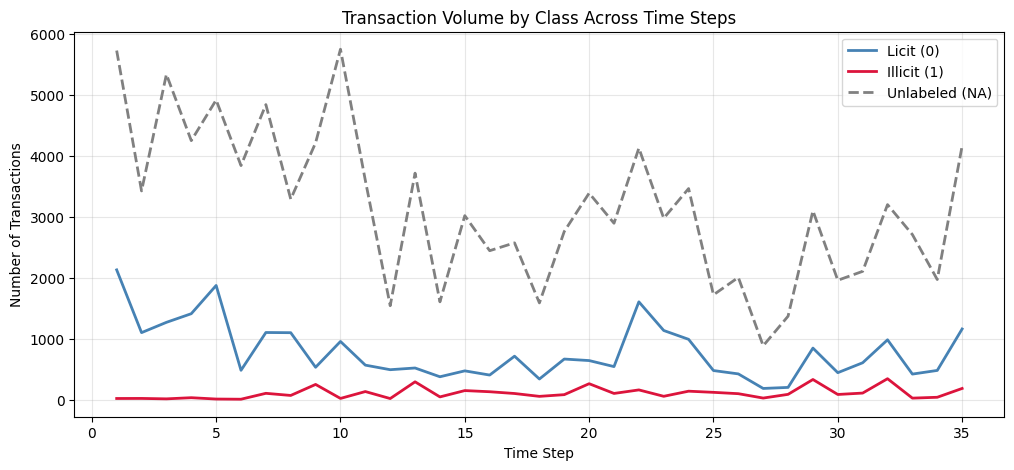

label_group,-1.0,0.0,1.0
time_step,,,
1,5733,2130,17
2,3427,1099,18
3,5342,1268,11
4,4253,1410,30
5,4921,1874,8
6,3843,480,5
7,4845,1101,102
8,3292,1098,67
9,4218,530,248


In [6]:
# Fill NaN with -1 temporarily so groupby includes missing labels as a column
time_label = (
    train_raw.assign(label_group=train_raw['label'].fillna(-1))
    .groupby(['time_step', 'label_group'])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(12, 5))
plt.plot(time_label.index, time_label[0.0], label='Licit (0)', color='steelblue', linewidth=2)
plt.plot(time_label.index, time_label[1.0], label='Illicit (1)', color='crimson', linewidth=2)
plt.plot(time_label.index, time_label[-1.0], label='Unlabeled (NA)', color='grey', linewidth=2, linestyle='--')

plt.title('Transaction Volume by Class Across Time Steps')
plt.xlabel('Time Step')
plt.ylabel('Number of Transactions')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

display(time_label)

As there is a high number of NA data (~77% of all provided training data),

I plan to use semi supervised learning. I will train a model on the existing labelled data, and then use it to label the NA data, and then train another model on it

Before using semi supervised learning, I need to assess if the labeled data is representative of the NA data which I want labelled
* I am running the ks_2samp test for each of the features in every time stamp
* due to the high number of tests (35 time steps * 173 features), the chances of false positives increase, thus the Benjamini-Hochberg procedure is applied to control false positives by adjusting the p values

In [7]:

data = train_raw.copy()

feature_cols = [c for c in data.columns if c not in ["txId", "label"]]
results = []

for time_step, step_data in data.groupby("time_step"):
    labelled = step_data[step_data["label"].notna()]
    unlabelled = step_data[step_data["label"].isna()]

    # Skip time steps that do not contain both groups
    if labelled.empty or unlabelled.empty:
        continue

    for col in feature_cols:
        labelled_values = labelled[col].dropna()
        unlabelled_values = unlabelled[col].dropna()

        if labelled_values.empty or unlabelled_values.empty:
            continue

        ks_stat, p_value = ks_2samp(labelled_values, unlabelled_values)

        pooled_sd = np.sqrt(
            (labelled_values.var() + unlabelled_values.var()) / 2
        )
        mean_diff_std = (
            (labelled_values.mean() - unlabelled_values.mean()) / pooled_sd
            if pooled_sd > 0 else 0
        )

        results.append({
            "time_step": time_step,
            "feature": col,
            "labelled_count": len(labelled_values),
            "na_count": len(unlabelled_values),
            "ks_statistic": ks_stat,
            "p_value": p_value,
            "mean_diff_std": mean_diff_std,
        })

comparison_by_step = pd.DataFrame(results)

def add_bh_correction(group):
    reject, p_adjusted, _, _ = multipletests(
        group["p_value"],
        alpha=0.05,
        method="fdr_bh"
    )

    group = group.copy()
    group["q_value"] = p_adjusted
    group["significant_after_correction"] = reject
    return group

comparison_by_step = (
    comparison_by_step
    .groupby("time_step", group_keys=False)
    .apply(add_bh_correction)
    .reset_index(drop=True)
)

display(comparison_by_step.sort_values("ks_statistic", ascending=False).head(10))

print("Features with significantly different NA vs Labeled distributions: ")
print(len(comparison_by_step[comparison_by_step["significant_after_correction"] == True]))

C:\Users\huawei 14\AppData\Local\Temp\ipykernel_40460\2439373577.py:58: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(add_bh_correction)


,time_step,feature,labelled_count,na_count,ks_statistic,p_value,mean_diff_std,q_value,significant_after_correction
5425,33,feat_113,441,2710,0.768915,3.651558e-228,2.160216,6.061587e-226,True
5427,33,feat_115,441,2710,0.758047,2.026105e-220,1.849316,1.681667e-218,True
1547,10,feat_53,972,5755,0.756002,1.521722e-321,1.700672,1.504973e-319,True
878,6,feat_48,485,3843,0.753340,1.127803e-247,0.464228,1.872153e-245,True
872,6,feat_42,485,3843,0.748956,3.325921e-244,0.472978,2.760515e-242,True
884,6,feat_54,485,3843,0.745554,1.560378e-241,0.897863,8.634091e-240,True
5439,33,feat_127,441,2710,0.740847,1.243699e-208,1.580898,6.881803e-207,True
5437,33,feat_125,441,2710,0.739002,2.127417e-207,1.699016,8.828782e-206,True
854,6,feat_24,485,3843,0.738810,2.543265e-236,0.349901,8.443639e-235,True
860,6,feat_30,485,3843,0.738810,2.543265e-236,0.349901,8.443639e-235,True


Features with significantly different NA vs Labeled distributions: 
5360


Plot out the top 10 feature distributions by ks_statistic - where ks_statistic indicates how different the distributions are

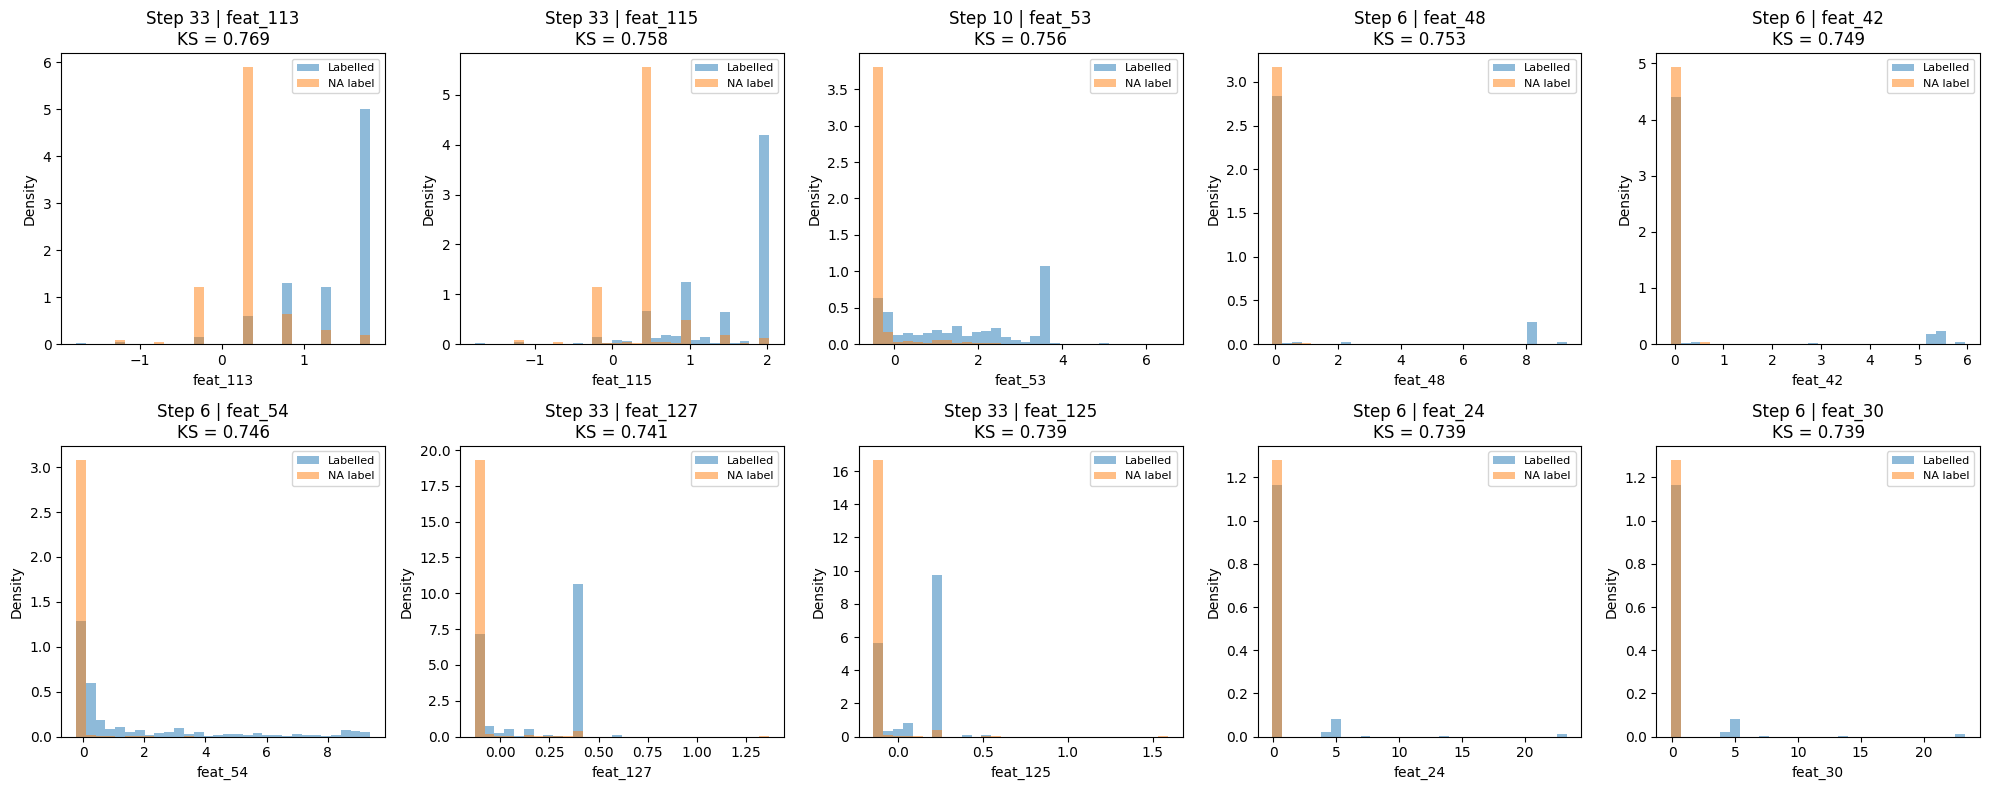

In [8]:


top10 = comparison_by_step.nlargest(10, "ks_statistic")

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top10.iterrows()):
    feature = row["feature"]
    step = row["time_step"]

    step_data = train_raw[train_raw["time_step"] == step]

    labelled_values = step_data.loc[
        step_data["label"].notna(), feature
    ].dropna()

    na_values = step_data.loc[
        step_data["label"].isna(), feature
    ].dropna()

    all_values = np.concatenate([labelled_values, na_values])
    bins = np.histogram_bin_edges(all_values, bins=30)

    # Normalize so the distribution shapes can be compared
    ax.hist(
        labelled_values, bins=bins, density=True,
        alpha=0.5, label="Labelled"
    )
    ax.hist(
        na_values, bins=bins, density=True,
        alpha=0.5, label="NA label"
    )

    ax.set_title(
        f"Step {step} | {feature}\n"
        f"KS = {row['ks_statistic']:.3f}"
    )
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()